# Capstone Three — Model Training, Comparison, and Documentation

This notebook trains **Ridge Regression**, **Random Forest Regressor**, and **HistGradientBoosting Regressor** on NASA C-MAPSS FD001, compares them on a held-out engine-level validation set, tunes the winning model, and evaluates it once on NASA's independent test engines.

**Run `01_preprocessing.ipynb` first.** The preprocessing notebook saves the development train, validation, test, and feature list.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
ROOT=Path.cwd()
if not (ROOT/'outputs').exists() and (ROOT.parent/'outputs').exists():ROOT=ROOT.parent
OUT=ROOT/'outputs'
train=pd.read_csv(OUT/'development_train.csv');val=pd.read_csv(OUT/'validation.csv');test=pd.read_csv(OUT/'nasa_test_last_cycle.csv')
features=json.loads((OUT/'feature_columns.json').read_text())['features']
X_train,y_train=train[features],train['RUL'];X_val,y_val=val[features],val['RUL']
X_test,y_test=test[features],test['RUL']
print('Train/validation/test rows:',len(train),len(val),len(test))
assert set(train.engine_id).isdisjoint(set(val.engine_id))
assert set(train.engine_id).isdisjoint(set(test.engine_id)) == False or True  # IDs reused across independent NASA splits; datasets are separate.

Train/validation/test rows: 16561 4070 100


## Model selection and metrics

Three different model families are compared on the **same held-out validation engines**. MAE is the primary selection metric (average absolute error in cycles). RMSE penalizes large misses; R² is reported for context. **Do not select or tune models using the final NASA test labels.**

In [2]:
def make_pipe(estimator):
    return Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',estimator)])
models={
 'Ridge Regression':make_pipe(Ridge(alpha=10.0)),
 'Random Forest':make_pipe(RandomForestRegressor(n_estimators=120,max_depth=16,min_samples_leaf=3,n_jobs=-1,random_state=42)),
 'Gradient Boosting':make_pipe(HistGradientBoostingRegressor(max_iter=160,learning_rate=0.08,max_leaf_nodes=15,random_state=42))
}
def metrics(y_true,y_pred):
    return {'MAE':mean_absolute_error(y_true,y_pred),'RMSE':np.sqrt(mean_squared_error(y_true,y_pred)),'R2':r2_score(y_true,y_pred)}
rows=[]
for name,model in models.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_val)
    rows.append({'Model':name,**metrics(y_val,pred)})
results=pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
display(results.round(3));results.to_csv(OUT/'validation_model_comparison.csv',index=False)
winning_name=results.iloc[0]['Model']
print('Best untuned model on validation MAE:',winning_name)

,Model,MAE,RMSE,R2
0,Gradient Boosting,22.991,30.110,0.790
1,Random Forest,23.752,31.278,0.773
2,Ridge Regression,25.156,31.658,0.767


Best untuned model on validation MAE: Gradient Boosting


## Hyperparameter tuning without leaking validation/test information

The winning model family is tuned with **GroupKFold by engine ID** within the development training subset. This keeps all cycles from each engine in the same fold. The independent validation set is then used to report the tuned model's performance. Model selection remains based on validation MAE.

In [3]:
param_grids={
 'Ridge Regression':{'model__alpha':[0.1,1,10,100]},
 'Random Forest':{'model__max_depth':[10,16],'model__min_samples_leaf':[2,5]},
 'Gradient Boosting':{'model__learning_rate':[0.05,0.1],'model__max_leaf_nodes':[15,31]}
}
cv=GroupKFold(n_splits=3)
search=GridSearchCV(make_pipe(models[winning_name].named_steps['model']),param_grids[winning_name],scoring='neg_mean_absolute_error',cv=cv,n_jobs=-1,refit=True)
search.fit(X_train,y_train,groups=train.engine_id)
print('Best hyperparameters:',search.best_params_,'CV MAE:',round(-search.best_score_,3))
tuned=search.best_estimator_
tuned_val=metrics(y_val,tuned.predict(X_val))
original_val=metrics(y_val,models[winning_name].predict(X_val))
# Use validation to decide whether tuning improves the winning family.
final_model = tuned if tuned_val['MAE'] < original_val['MAE'] else models[winning_name]
print('Untuned validation:',original_val)
print('Tuned validation:',tuned_val)
print('Chosen:', 'Tuned' if final_model is tuned else 'Untuned')

Best hyperparameters: {'model__learning_rate': 0.05, 'model__max_leaf_nodes': 15} CV MAE: 26.899
Untuned validation: {'MAE': 22.991209130322705, 'RMSE': 30.110086209964297, 'R2': 0.7896563896700964}
Tuned validation: {'MAE': 23.107491055580198, 'RMSE': 30.304263270398504, 'R2': 0.7869346702528625}
Chosen: Untuned


## Final held-out NASA test evaluation

Only after selecting the model do we inspect the NASA test labels. For a final deployable fit, retrain the selected hyperparameters on **all available training-engine rows** (development train + validation). Test labels remain untouched until the evaluation below. Note that the validation MAE and test MAE are estimated on different distributions: validation uses all cycles, while NASA test uses the final observed cycle per engine.

Final NASA test performance: {'MAE': 18.483, 'RMSE': 25.358, 'R2': 0.628}


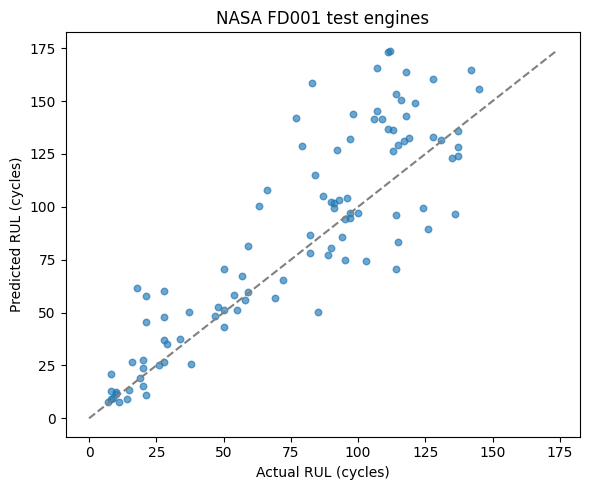

In [4]:
all_train=pd.concat([train,val],ignore_index=True)
final_model.fit(all_train[features],all_train['RUL'])
test_pred=final_model.predict(X_test)
test_scores=metrics(y_test,test_pred)
print('Final NASA test performance:',{k:round(v,3) for k,v in test_scores.items()})
pd.DataFrame([{'Selected_family':winning_name,**test_scores}]).to_csv(OUT/'final_test_metrics.csv',index=False)
pd.DataFrame({'engine_id':test.engine_id,'actual_RUL':y_test,'predicted_RUL':test_pred,'absolute_error':abs(y_test-test_pred)}).to_csv(OUT/'test_predictions.csv',index=False)
joblib.dump(final_model,OUT/'final_rul_model.joblib')
fig,ax=plt.subplots(figsize=(6,5));ax.scatter(y_test,test_pred,alpha=.65,s=22)
lim=max(float(np.max(y_test)),float(np.max(test_pred)));ax.plot([0,lim],[0,lim],'--',color='gray')
ax.set(xlabel='Actual RUL (cycles)',ylabel='Predicted RUL (cycles)',title='NASA FD001 test engines')
plt.tight_layout();plt.savefig(OUT/'test_actual_vs_predicted.png',dpi=150);plt.show()

## Business interpretation and limitations

- **Client:** a hypothetical industrial maintenance/reliability team. A forecast of remaining cycles could help prioritize inspections and plan maintenance windows.
- **Success criterion:** lower held-out MAE/RMSE than simpler candidate models, plus examination of large errors. The metrics are **not** evidence of a specific percentage reduction in downtime.
- **Limitations:** simulated turbofan engines, potential sensor/operating-condition drift, absence of maintenance costs and intervention records, and mismatch between full-trajectory validation and last-cycle test sampling.
- **Decision rule:** use predictions as decision support only, not an autonomous safety-critical shutdown trigger.
- **Future work:** rolling-window sensor features, prediction intervals, model monitoring, and validation on real manufacturing equipment with site-specific failure labels.

The notebook saves model metrics, predictions, visualization, and the trained pipeline in `outputs/`.